# Parte 1 — Dataset y preprocesamiento

Notebook de documentacion, tratamiento de datos y entrenamiento.

## Equipo
- Máximo Alva
- Zahir Jacob

## Configuración del entorno

In [2]:
from pathlib import Path
from dotenv import dotenv_values
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from tqdm.auto import tqdm
from scipy.stats import spearmanr

In [3]:
DATA_DIR = Path("./data/CelebA")
IMGS_DIR = DATA_DIR / "Img" / "img_align_celeba"
ANNO_DIR = DATA_DIR / "Anno"

IDENTITY_PATH = ANNO_DIR / "identity_CelebA.txt"
ATTR_PATH = ANNO_DIR / "list_attr_celeba.txt"
BBOX_PATH = ANNO_DIR / "list_bbox_celeba.txt"
LANDMARKS_PATH = ANNO_DIR / "list_landmarks_align_celeba.txt"

IMGS_DIR.mkdir(parents=True, exist_ok=True)
ANNO_DIR.mkdir(parents=True, exist_ok=True)

In [4]:
ENV = dotenv_values(".env.local.example")

FACE_SIZE = int(ENV["FACE_SIZE"])
MIN_FACE_SIZE = int(ENV["MIN_FACE_SIZE"])

In [5]:
# Parámetros de selección del subconjunto
UMBRAL_IDENTITY = 21 # Mínimo de imágenes por identidad
N_IDENTITIES = 1000 # Cantidad de identidades a muestrear al azar
MIN_IMGS_FINAL = 15 # Mínimo de imágenes por identidad después de la limpieza

SEED = 42

In [6]:
def _to_rgb(img: str | Path | np.ndarray) -> np.ndarray:
    """
    Convierte una imagen BGR (OpenCV) o un archivo a RGB (matplotlib).
    
    Args:
        img: Ruta del archivo de imagen o array de imagen BGR.

    Returns:
        np.ndarray: Imagen en formato RGB.
    """
    # Si la entrada es una ruta de archivo, abrirla y convertirla a RGB
    if isinstance(img, (str, Path)):
        return np.asarray(Image.open(img).convert("RGB"))
    
    # Si la imagen es un array de 2 dimensiones, escala de grises    
    if img.ndim == 2:
        return img
    
    # Si la imagen es un array de 3 dimensiones, convertir de BGR a RGB
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

In [7]:
def show_images(imgs, titles=None, ncols=5, size=(14, 4), suptitle=None):
    """
    Muestra una lista de imágenes en una cuadrícula.
    
    Args:
        imgs: Lista de rutas de imágenes o arrays de imágenes.
        titles: Lista de títulos para cada imagen (opcional).
        ncols: Número de columnas en la cuadrícula.
        size: Tamaño de la figura (ancho, alto).
        suptitle: Título general para la figura (opcional).
    """
    imgs = list(imgs)
    titles = list(titles) if titles is not None else [None] * len(imgs)
    nrows = int(np.ceil(len(imgs) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size[0], size[1]))
    for ax in axes.flat:
        ax.axis("off")
    for ax, img, title in zip(axes.flat, imgs, titles):
        ax.imshow(_to_rgb(img), cmap="gray")
        if title:
            ax.set_title(title, fontsize=10)
    if suptitle:
        fig.suptitle(suptitle, fontsize=14)
    plt.tight_layout()
    plt.show()

In [8]:
def read_header(path: str | Path) -> tuple[str | None, str | None, int | float, int | float, bool]:
    """
    Lee el encabezado de una imagen y devuelve su formato, modo y dimensiones.
    
    Args:
        path (str | Path): Ruta a la imagen.
        
    Returns:
        tuple[str | None, str | None, int | float, int | float, bool]: Tupla con el formato, modo y dimensiones de la imagen.
    """
    try:
        with Image.open(path) as im:
            return im.format, im.mode, im.size[0], im.size[1], True
    except Exception:
        return None, None, np.nan, np.nan, False

## Elección del dataset: CelebA

Para este proyecto de detección y reconocimiento de rostros, hemos seleccionado el dataset **Large-scale CelebFaces Attributes (CelebA)**.

Según su [documentación oficial](https://mmlab.ie.cuhk.edu.hk/projects/CelebA.html):

> CelebFaces Attributes Dataset (CelebA) is a large-scale face attributes dataset with more than **200K** celebrity images, each with **40** attribute annotations. The images in this dataset cover large pose variations and background clutter. CelebA has large diversities, large quantities, and rich annotations, including:
> * **10,177** number of **identities**
> * **202,599** number of **face images**
> * **5 landmark locations** per image
> * **40 binary attributes** annotations per image
>
> The dataset can be employed as the training and test sets for the following computer vision tasks: face attribute recognition, face recognition, face detection, landmark (or facial part) localization, and face editing & synthesis.

Descripción de los archivos a utilizar:

| Archivo | Descripción | Uso en este trabajo |
|---|---|---|
| `img_align_celeba/` | Imágenes ya centradas y recortadas, todas de 178×218 | Imágenes de trabajo |
| `identity_CelebA.txt` | Identidad de cada imagen | Etiqueta de clase |
| `list_attr_celeba.txt` | 40 atributos binarios por imagen (`1` / `-1`) anotados a mano | Indicadores aproximados (tienen ruido) para el EDA de expresión, oclusiones y demografía (`Eyeglasses`, `Wearing_Hat`, `Smiling`, `Male`, `Young`, `Pale_Skin`, etc.), para validar la regla de nitidez contra `Blurry` y para cuantificar el sesgo demográfico. **No** se usan como entrada ni como objetivo del modelo |
| `list_landmarks_align_celeba.txt` | Landmarks sobre `img_align_celeba` | Referencia para validar nuestro detector y para el EDA de pose |
| `list_bbox_celeba.txt` | Bounding boxes sobre las imágenes originales sin recortar `img_celeba` (*in the wild*) | Las usamos sólo como medida del tamaño del rostro en la foto de origen |

Elegimos este dataset principalmente debido a su tamaño y cantidad de imágenes por identidad, esto nos brinda la flexibilidad necesaria para poder seleccionar un subconjunto del mismo adaptado especialmente a nuestras necesidades y criterio, garantizando la reproducibilidad en todo el proceso. El dataset incluye variaciones significativas en pose, iluminación, accesorios y expresiones, lo cual provee un entorno desafiante pero realista para entrenar un sistema de reconocimiento facial robusto. El dataset viene acompañado de archivos `.txt` que agregan anotaciones que pueden resultar útiles como coordenadas de bounding boxes, landmarks y otros atributos binarios.

Finalmente, reconocemos como limitación que el dataset arrastra un sesgo demográfico inherente a la industria del entretenimiento (en rangos de edad, tonos de piel, género, etc.), sumado a ciertas disparidades de calidad que abordaremos en las etapas de limpieza.

### Descarga

https://drive.google.com/drive/folders/0B7EVK8r0v71pWEZsZE9oNnFzTm8

https://www.kaggle.com/datasets/khnhhong/celeba

In [9]:
# Completar descargas

### Cargar dataframes

#### Identity

In [10]:
df_identity = pd.read_csv(IDENTITY_PATH, sep=" ", header=None, names=["image_id", "identity"])
df_identity

,image_id,identity
0,000001.jpg,2880
1,000002.jpg,2937
2,000003.jpg,8692
3,000004.jpg,5805
4,000005.jpg,9295
...,...,...
202594,202595.jpg,9761
202595,202596.jpg,7192
202596,202597.jpg,9852
202597,202598.jpg,5570


#### Attr

In [11]:
df_attr = pd.read_csv(ATTR_PATH, sep=r'\s+',skiprows=1)
df_attr.reset_index(inplace=True)
df_attr.rename(columns={df_attr.columns[0]: 'image_id'}, inplace=True)
attr_cols = df_attr.columns.drop("image_id")
df_attr[attr_cols] = df_attr[attr_cols].replace({-1: 0})
df_attr

,image_id,5_o_Clock_Shadow,Arched_Eyebrows,Attractive,Bags_Under_Eyes,Bald,Bangs,Big_Lips,Big_Nose,Black_Hair,...,Sideburns,Smiling,Straight_Hair,Wavy_Hair,Wearing_Earrings,Wearing_Hat,Wearing_Lipstick,Wearing_Necklace,Wearing_Necktie,Young
0,000001.jpg,0,1,1,0,0,0,0,0,0,...,0,1,1,0,1,0,1,0,0,1
1,000002.jpg,0,0,0,1,0,0,0,1,0,...,0,1,0,0,0,0,0,0,0,1
2,000003.jpg,0,0,0,0,0,0,1,0,0,...,0,0,0,1,0,0,0,0,0,1
3,000004.jpg,0,0,1,0,0,0,0,0,0,...,0,0,1,0,1,0,1,1,0,1
4,000005.jpg,0,1,1,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
202594,202595.jpg,0,0,1,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
202595,202596.jpg,0,0,0,0,0,1,1,0,0,...,0,1,1,0,0,0,0,0,0,1
202596,202597.jpg,0,0,0,0,0,0,0,0,1,...,0,1,0,0,0,0,0,0,0,1
202597,202598.jpg,0,1,1,0,0,0,1,0,1,...,0,1,0,1,1,0,1,0,0,1


#### Bbox

In [12]:
df_bbox = pd.read_csv(BBOX_PATH, sep=r'\s+', skiprows=1)
df_bbox.rename(columns={'x_1': 'orig_bbox_x1', 'y_1': 'orig_bbox_y1', 'width': 'orig_bbox_width', 'height': 'orig_bbox_height'}, inplace=True)
df_bbox

,image_id,orig_bbox_x1,orig_bbox_y1,orig_bbox_width,orig_bbox_height
0,000001.jpg,95,71,226,313
1,000002.jpg,72,94,221,306
2,000003.jpg,216,59,91,126
3,000004.jpg,622,257,564,781
4,000005.jpg,236,109,120,166
...,...,...,...,...,...
202594,202595.jpg,1381,91,221,306
202595,202596.jpg,137,129,114,158
202596,202597.jpg,53,76,91,126
202597,202598.jpg,195,28,91,126


#### Landmarks

In [13]:
df_landmarks = pd.read_csv(LANDMARKS_PATH, sep=r'\s+', skiprows=1)
df_landmarks.reset_index(inplace=True)
df_landmarks.rename(columns={df_landmarks.columns[0]: 'image_id'}, inplace=True)
df_landmarks

,image_id,lefteye_x,lefteye_y,righteye_x,righteye_y,nose_x,nose_y,leftmouth_x,leftmouth_y,rightmouth_x,rightmouth_y
0,000001.jpg,69,109,106,113,77,142,73,152,108,154
1,000002.jpg,69,110,107,112,81,135,70,151,108,153
2,000003.jpg,76,112,104,106,108,128,74,156,98,158
3,000004.jpg,72,113,108,108,101,138,71,155,101,151
4,000005.jpg,66,114,112,112,86,119,71,147,104,150
...,...,...,...,...,...,...,...,...,...,...,...
202594,202595.jpg,69,111,108,111,89,140,73,151,104,153
202595,202596.jpg,67,112,110,112,85,141,66,150,110,150
202596,202597.jpg,69,111,107,111,92,137,68,151,109,153
202597,202598.jpg,69,111,108,111,90,137,71,153,106,151


### Unir dataframes

In [14]:
# Unificar todos los dataframes usando 'image_id' como primary key
df_celeba = df_identity.merge(df_attr, on='image_id', how='inner')
df_celeba = df_celeba.merge(df_bbox, on='image_id', how='inner')
df_celeba = df_celeba.merge(df_landmarks, on='image_id', how='inner')
df_celeba

,image_id,identity,5_o_Clock_Shadow,Arched_Eyebrows,Attractive,Bags_Under_Eyes,Bald,Bangs,Big_Lips,Big_Nose,...,lefteye_x,lefteye_y,righteye_x,righteye_y,nose_x,nose_y,leftmouth_x,leftmouth_y,rightmouth_x,rightmouth_y
0,000001.jpg,2880,0,1,1,0,0,0,0,0,...,69,109,106,113,77,142,73,152,108,154
1,000002.jpg,2937,0,0,0,1,0,0,0,1,...,69,110,107,112,81,135,70,151,108,153
2,000003.jpg,8692,0,0,0,0,0,0,1,0,...,76,112,104,106,108,128,74,156,98,158
3,000004.jpg,5805,0,0,1,0,0,0,0,0,...,72,113,108,108,101,138,71,155,101,151
4,000005.jpg,9295,0,1,1,0,0,0,1,0,...,66,114,112,112,86,119,71,147,104,150
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
202594,202595.jpg,9761,0,0,1,0,0,0,1,0,...,69,111,108,111,89,140,73,151,104,153
202595,202596.jpg,7192,0,0,0,0,0,1,1,0,...,67,112,110,112,85,141,66,150,110,150
202596,202597.jpg,9852,0,0,0,0,0,0,0,0,...,69,111,107,111,92,137,68,151,109,153
202597,202598.jpg,5570,0,1,1,0,0,0,1,0,...,69,111,108,111,90,137,71,153,106,151


## Análisis exploratorio (EDA)

### Imágenes por identidad y desbalance de clases


Este análisis lo realizamos sobre sobre el dataset completo. Es la información que necesitamos para poder decidir sobre qué subconjunto trabajar y que umbral utilizar para corregir el desbalance de imágenes por identidad.

In [15]:
print(f"Total de imágenes en {IMGS_DIR}: {len(list(IMGS_DIR.glob('*.jpg')))}")
print(f"Total de registros en dataframe: {len(df_celeba)}")

Total de imágenes en data\CelebA\Img\img_align_celeba: 202599
Total de registros en dataframe: 202599


In [16]:
print(f"Total de identidades únicas: {df_celeba['identity'].nunique()}")

Total de identidades únicas: 10177


In [17]:
identity_counts = df_celeba["identity"].value_counts()
print(identity_counts)

identity
2820    35
3782    35
3227    35
3745    34
3699    34
        ..
4273     1
2708     1
8565     1
8585     1
7778     1
Name: count, Length: 10177, dtype: int64


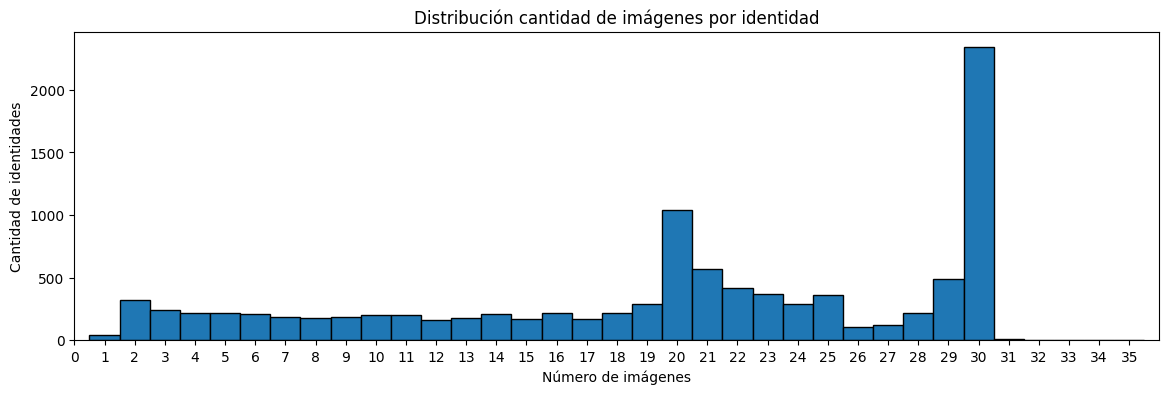

In [18]:
# Gráfico de distribución
identity_counts_max = identity_counts.max()
plt.figure(figsize=(14, 4))
bins = np.arange(1, identity_counts_max + 2) - 0.5
plt.hist(identity_counts, bins=bins, edgecolor='black')
plt.xlim(0, identity_counts_max + 1)
plt.xticks(range(0, identity_counts_max + 1))
plt.title("Distribución cantidad de imágenes por identidad")
plt.xlabel("Número de imágenes")
plt.ylabel("Cantidad de identidades")
plt.show()

In [19]:
print(identity_counts.describe())

count    10177.000000
mean        19.907537
std          8.925916
min          1.000000
25%         13.000000
50%         21.000000
75%         29.000000
max         35.000000
Name: count, dtype: float64


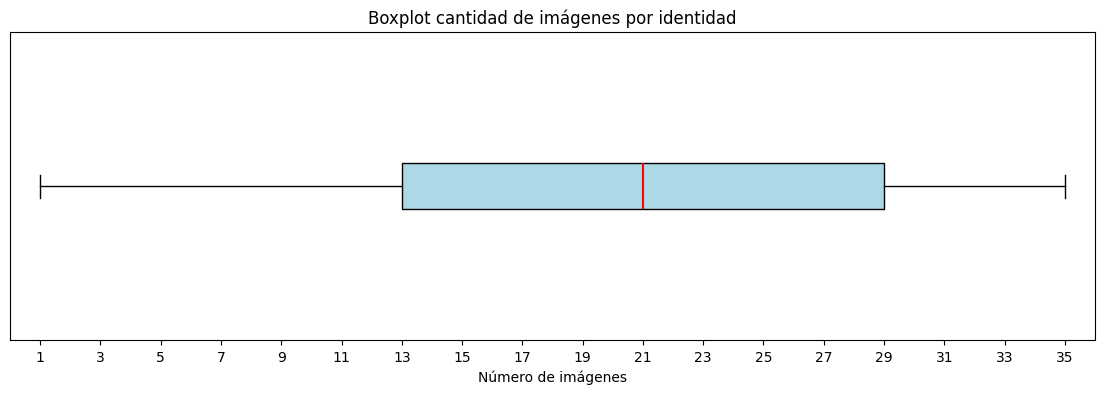

In [20]:
# Boxplot
plt.figure(figsize=(14, 4))
plt.boxplot(identity_counts, vert=False, patch_artist=True, boxprops=dict(facecolor='lightblue', color='black'), medianprops=dict(color='red', linewidth=1.5))
plt.xlim(0, identity_counts_max + 1)
plt.xticks(range(1, identity_counts_max + 1, 2))
plt.title("Boxplot cantidad de imágenes por identidad")
plt.xlabel("Número de imágenes")
plt.gca().axes.get_yaxis().set_visible(False)
plt.show()

In [21]:
n_ids = len(identity_counts)
rows = []
for t in [1, 5, 10, 15, 20, 21, 25, 30]:
    kept = identity_counts[identity_counts >= t]
    rows.append({
        "umbral (≥)": t,
        "identidades": len(kept),
        "% identidades": 100 * len(kept) / n_ids,
        "imágenes": int(kept.sum()),
        "% imágenes": 100 * kept.sum() / identity_counts.sum(),
        "desbalance máx/mín": kept.max() / kept.min(),
    })
df_thr = pd.DataFrame(rows).round(2)
df_thr

,umbral (≥),identidades,% identidades,imágenes,% imágenes,desbalance máx/mín
0,1,10177,100.00,202599,100.00,35.00
1,5,9343,91.81,200288,98.86,7.00
2,10,8369,82.23,193569,95.54,3.50
3,15,7417,72.88,182152,89.91,2.33
4,20,6348,62.38,163749,80.82,1.75
5,21,5304,52.12,142869,70.52,1.67
6,25,3661,35.97,106339,52.49,1.40
7,30,2360,23.19,70838,34.96,1.17


### Elección del umbral de imágenes por identidad y el tamaño del subconjunto

Teniendo en cuenta que el enunciado recomienda un mínimo de 10 a 20 imágenes por persona, elegimos establecer el `UMBRAL_IDENTITY = 21` (umbral de imágenes por identidad), lo que deja margen para la limpieza posterior, que va a descartar algunas imágenes; por ello, al final del proceso exigimos `MIN_IMGS_FINAL = 15`. Al ser 21 la mediana de la distribución, nos estamos quedando con la mitad de las identidades que más imágenes tienen. Además el desbalance desciende de 35 a ≈ 1,67, por lo que casi no hace falta re-balancear durante el entrenamiento.

Cada identidad de entrenamiento se divide 80/10/10 entre `train`, `val_closed` y `test_closed`: con 21 imágenes quedan unas 17 para entrenar y al menos 2 para evaluar.

Con este umbral, las identidades elegibles superan las 5.000, con más de 140.000 imágenes. Decidimos quedarnos con `N_IDENTITIES = 1000`, elegidas al azar con semilla fija, del orden de 28.000 imágenes. Consideramos que es un tamaño suficiente para entrenar una CNN de clasificación con unas 700 clases y evaluar sobre unas 150 identidades nunca vistas, y reduce considerablemente el costo computacional de la detección, la alineación y la extracción de embeddings.

In [22]:
eligible_ids = identity_counts[identity_counts >= UMBRAL_IDENTITY].index.to_numpy()
rng_subset = np.random.default_rng(SEED)

if N_IDENTITIES is not None and N_IDENTITIES < len(eligible_ids):
    selected_ids = np.sort(rng_subset.choice(eligible_ids, size=N_IDENTITIES, replace=False))
else:
    selected_ids = np.sort(eligible_ids)

df = df_celeba[df_celeba["identity"].isin(selected_ids)].reset_index(drop=True).copy()
df["src_path"] = df["image_id"].map(lambda f: str(IMGS_DIR / f))

print(f"Identidades elegibles (≥ {UMBRAL_IDENTITY} imágenes): {len(eligible_ids)}")
print(f"Subconjunto: {df['identity'].nunique()} identidades, {len(df)} imágenes")
df["identity"].value_counts().describe().round(2)

Identidades elegibles (≥ 21 imágenes): 5304
Subconjunto: 1000 identidades, 26917 imágenes


count    1000.00
mean       26.92
std         3.46
min        21.00
25%        23.00
50%        29.00
75%        30.00
max        30.00
Name: count, dtype: float64

### Muestra visual

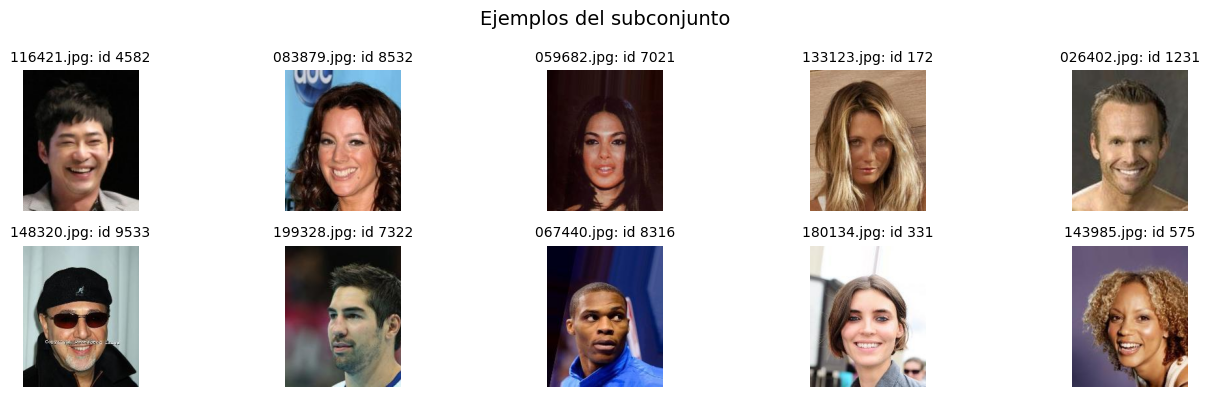

In [ ]:
# 8 imágenes al azar del subconjunto
sample_df = df.sample(n=10, random_state=SEED).reset_index(drop=True)
show_images(sample_df["src_path"], titles=[f"{r.image_id}; id {r.identity}" for r in sample_df.itertuples()], suptitle="Ejemplos del subconjunto")

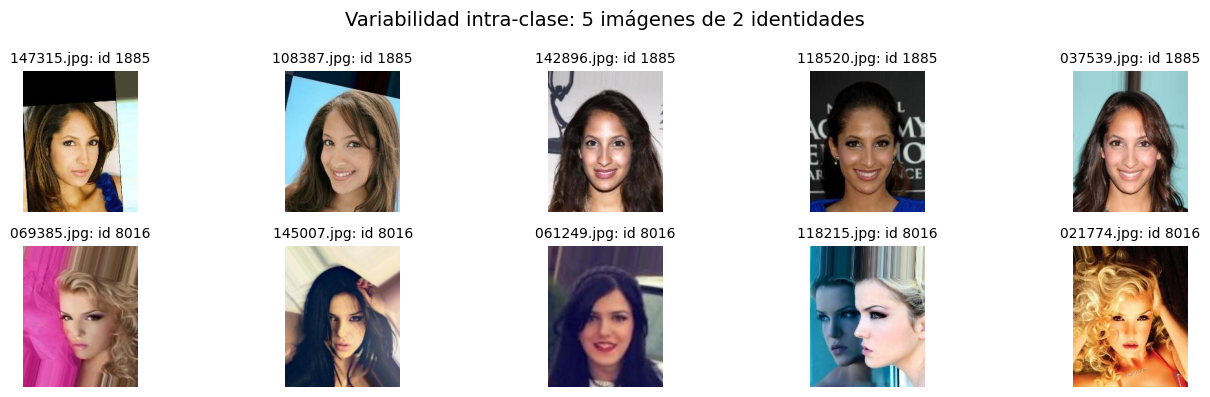

In [ ]:
# Variabilidad intra-clase: 5 imágenes de 2 identidades
show_ids = np.random.default_rng(SEED).choice(df["identity"].unique(), size=2, replace=False)
imgs, titles = [], []
for ident in show_ids:
    rows_id = df[df["identity"] == ident].sample(n=5, random_state=SEED)
    imgs += rows_id["src_path"].tolist()
    titles += [f"{r.image_id}; id {r.identity}" for r in rows_id.itertuples()]
show_images(imgs, titles=titles, suptitle="Variabilidad intra-clase: 5 imágenes de 2 identidades")

### Formato, canales e integridad de archivos

Leemos el encabezado de cada archivo.

In [25]:
hdr = pd.DataFrame([read_header(p) for p in tqdm(df["src_path"], desc="encabezados")], columns=["fmt", "mode", "img_w", "img_h", "header_ok"], index=df.index)
df = df.drop(columns=hdr.columns, errors="ignore").join(hdr)

print("Formato   :", df["fmt"].value_counts(dropna=False).to_dict())
print("Modo      :", df["mode"].value_counts(dropna=False).to_dict())
print("Extensión :", df["src_path"].map(lambda p: Path(p).suffix.lower()).value_counts().to_dict())
print("Ilegibles :", int((~df["header_ok"]).sum()))
df.groupby(["img_w", "img_h"]).size().rename("imágenes").sort_values(ascending=False).head()

encabezados: 100%|██████████| 26917/26917 [03:43<00:00, 120.62it/s]


Formato   : {'JPEG': 26917}
Modo      : {'RGB': 26917}
Extensión : {'.jpg': 26917}
Ilegibles : 0


img_w  img_h
178    218      26917
Name: imágenes, dtype: int64

Las 26.917 imágenes del subconjunto son archivos JPEG en modo RGB, con extensión `.jpg`, y todas tienen la misma resolución de 178×218 píxeles. No encontramos archivos ilegibles.

Esta verificación sólo lee el encabezado de cada archivo; la decodificación completa de la imagen se comprueba en la etapa de detección, donde una imagen que no se pueda abrir se descarta como corrupta.

Que todas las imágenes estén en modo RGB no significa que todas sean a color, una foto en blanco y negro guardada como RGB tiene los tres canales iguales. Las detectaremos más adelante a partir de la saturación.

Como CelebA entrega todas las imágenes recortadas al mismo tamaño, la resolución del archivo no permite distinguir imágenes de mejor o peor calidad. Por eso, en la sección siguiente analizaremos el tamaño que tenía el rostro en la foto original.

### Resoluciones y tamaño del rostro

Como todas las imágenes de `img_align_celeba` tienen el mismo tamaño (178×218, relación de aspecto ≈ 0,82), la resolución del archivo no nos dice nada sobre su calidad. Lo que importa es cuánto medía el rostro en la foto original, si allí medía 40 px, CelebA la amplió para llevarla a 178×218 perdiendo detalle real. Para medirlo usaremos el **ancho del rostro en la foto original** (`orig_bbox_width` de `list_bbox_celeba.txt`), comparado con `MIN_FACE_PX` y con `FACE_SIZE`.

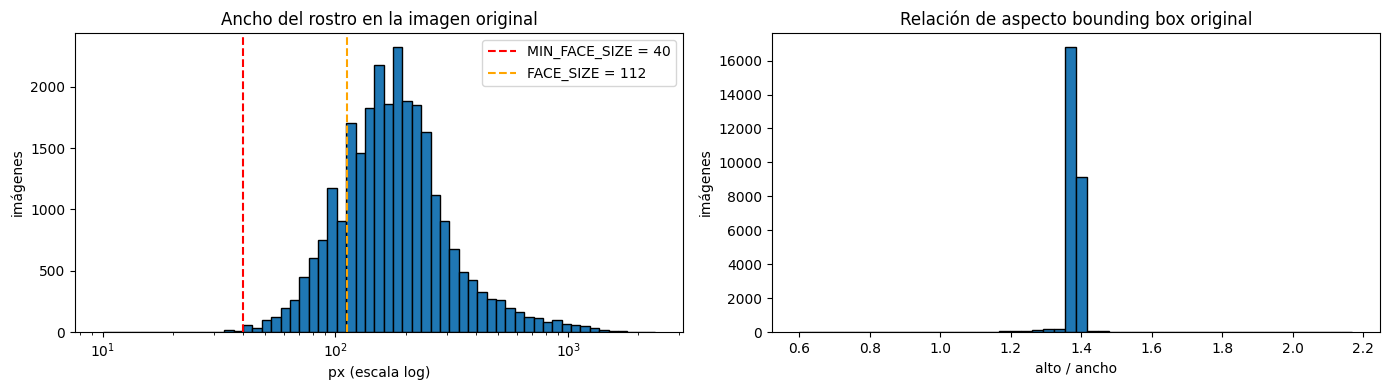

Ancho del rostro en la imagen original: mediana 174 px, mínimo 10 px, máximo 2366 px


In [ ]:
w = df["orig_bbox_width"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(w, bins=np.logspace(np.log10(max(w.min(), 1)), np.log10(w.max()), 60), edgecolor="black")
axes[0].set_xscale("log")
axes[0].axvline(MIN_FACE_SIZE, color="red", ls="--", label=f"MIN_FACE_SIZE = {MIN_FACE_SIZE}")
axes[0].axvline(FACE_SIZE, color="orange", ls="--", label=f"FACE_SIZE = {FACE_SIZE}")
axes[0].set(title="Ancho del rostro en la imagen original", xlabel="px (escala log)", ylabel="imágenes")
axes[0].legend()

axes[1].hist(df["orig_bbox_height"] / w, bins=50, edgecolor="black")
axes[1].set(title="Relación de aspecto bounding box original", xlabel="alto / ancho", ylabel="imágenes")

plt.tight_layout()
plt.show()

print(f"Ancho del rostro en la imagen original: mediana {w.median():.0f} px, mínimo {w.min()} px, máximo {w.max()} px")

In [27]:
# Rostros chicos
print(f"Rostros < 20 px: {(w < 20).sum()} ({100 * (w < 20).mean():.2f}%)")
print(f"Rostros < {MIN_FACE_SIZE} px: {(w < MIN_FACE_SIZE).sum()} ({100 * (w < MIN_FACE_SIZE).mean():.2f}%)")
print(f"Rostros < {FACE_SIZE} px: {(w < FACE_SIZE).sum()} ({100 * (w < FACE_SIZE).mean():.2f}%)")
print(f"Rostros >= {FACE_SIZE} px: {(w >= FACE_SIZE).sum()} ({100 * (w >= FACE_SIZE).mean():.2f}%)")

Rostros < 20 px: 7 (0.03%)
Rostros < 40 px: 40 (0.15%)
Rostros < 112 px: 4704 (17.48%)
Rostros >= 112 px: 22213 (82.52%)


El ancho del rostro en la imagen original es muy asimétrico, con una cola larga hacia los rostros grandes: la mediana es de 174 px y los valores van de 10 a 2.366 px. El 82,52% de las imágenes (22.213) proviene de rostros de al menos 112 px, que al llevarse a `FACE_SIZE` se reducen sin perder detalle. El 17,48% restante (4.704 imágenes) corresponde a rostros más chicos, que CelebA amplió y que tienen menos detalle real del que aparenta su resolución. Entre ellos, los rostros realmente chicos son muy pocos: 40 imágenes (0,15%) miden menos de 40 px, y sólo 7 (0,03%) menos de 20 px.

La relación de aspecto de las cajas es casi constante (alto/ancho ≈ 1,39), salvo en algunos casos.

Fijamos `MIN_FACE_SIZE = 40`, el mismo valor que usa la app. En este dataset, subir el mínimo de 20 a 40 px descarta sólo 33 imágenes más; el valor importa sobre todo en la app, donde un rostro de 20 px ampliado a 112×112 produce un embedding poco confiable.

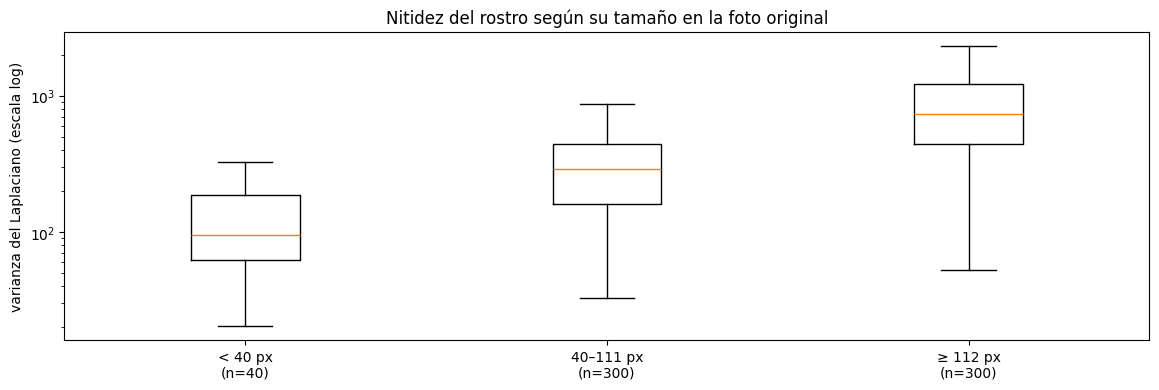

Correlación de Spearman entre tamaño original y nitidez: 0.68 (p = 2.6e-86)


In [28]:
size_labels = [f"< {MIN_FACE_SIZE} px", f"{MIN_FACE_SIZE}–{FACE_SIZE - 1} px", f"≥ {FACE_SIZE} px"]
df["orig_face_size"] = pd.cut(w, bins=[0, MIN_FACE_SIZE, FACE_SIZE, np.inf], labels=size_labels, right=False)

# Muestra de hasta 300 imágenes por grupo (el grupo < 40 px tiene sólo 40)
parts = [g.sample(n=min(300, len(g)), random_state=SEED) for _, g in df.groupby("orig_face_size", observed=True)]
sharp = pd.concat(parts)
sharp["sharpness"] = [
    cv2.Laplacian(cv2.imread(p, cv2.IMREAD_GRAYSCALE)[75:185, 45:133], cv2.CV_64F).var()
    for p in sharp["src_path"]
]

groups = [sharp.loc[sharp["orig_face_size"] == lab, "sharpness"] for lab in size_labels]
plt.figure(figsize=(14, 4))
plt.boxplot(groups, tick_labels=[f"{lab}\n(n={len(g)})" for lab, g in zip(size_labels, groups)], showfliers=False)
plt.yscale("log")
plt.ylabel("varianza del Laplaciano (escala log)")
plt.title("Nitidez del rostro según su tamaño en la foto original")
plt.show()

rho, pval = spearmanr(sharp["orig_bbox_width"], sharp["sharpness"])
print(f"Correlación de Spearman entre tamaño original y nitidez: {rho:.2f} (p = {pval:.1e})")

Para verificar que los rostros pequeños en la imagen original efectivamente tienen menos detalle, medimos la nitidez de la zona del rostro (varianza del Laplaciano) en una muestra de cada grupo. La mediana pasa de ≈ 95 en los rostros de menos de 40 px a ≈ 290 entre 40 y 111 px y a ≈ 750 en los de al menos 112 px, con una correlación de Spearman de 0,68 entre el tamaño original y la nitidez. Esto respalda descartar los rostros menores a `MIN_FACE_SIZE`. El grupo intermedio también es menos nítido, pero representa el 17% del dataset, así que no lo descartamos por tamaño. Como los grupos se superponen, el tamaño original no alcanza para decidir la calidad de una imagen, y por eso el control de calidad mide la nitidez directamente sobre cada recorte.

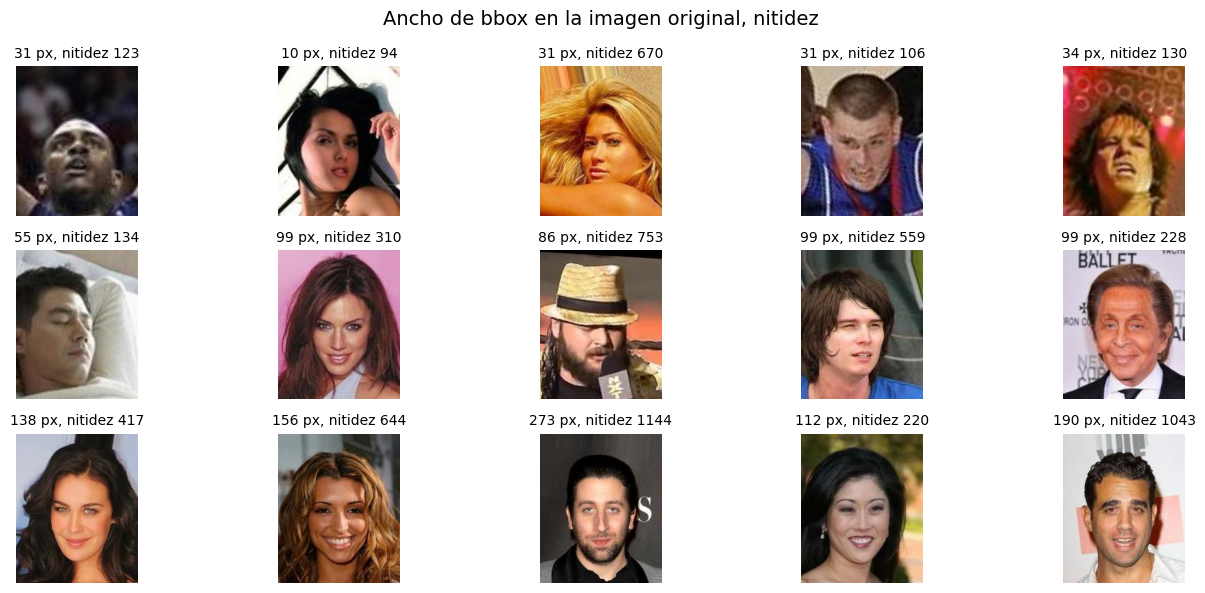

In [ ]:
imgs, titles = [], []
for lab in size_labels:
    rows_g = sharp[sharp["orig_face_size"] == lab].sample(n=5, random_state=SEED)
    imgs += rows_g["src_path"].tolist()
    titles += [f"{r.orig_bbox_width} px; nitidez = {r.sharpness:.0f}" for r in rows_g.itertuples()]

show_images(imgs, titles=titles, ncols=5, size=(14, 6), suptitle=f"Ancho de bbox en la imagen original, nitidez")

La grilla confirma visualmente la tendencia, los rostros que medían menos de 40 px en el original se ven pixelados o borrosos, mientras que los de al menos 112 px tienen buena calidad.

### Variaciones

Estas variaciones son las que el modelo tiene que tolerar para reconocer a una misma persona en fotos distintas. La iluminación y el color los medimos directamente sobre los píxeles de la zona del rostro, en una muestra. La pose la estimamos a partir de los landmarks de CelebA, y la expresión y las oclusiones a partir de los atributos anotados a mano del dataset.

#### Iluminación

#### Pose

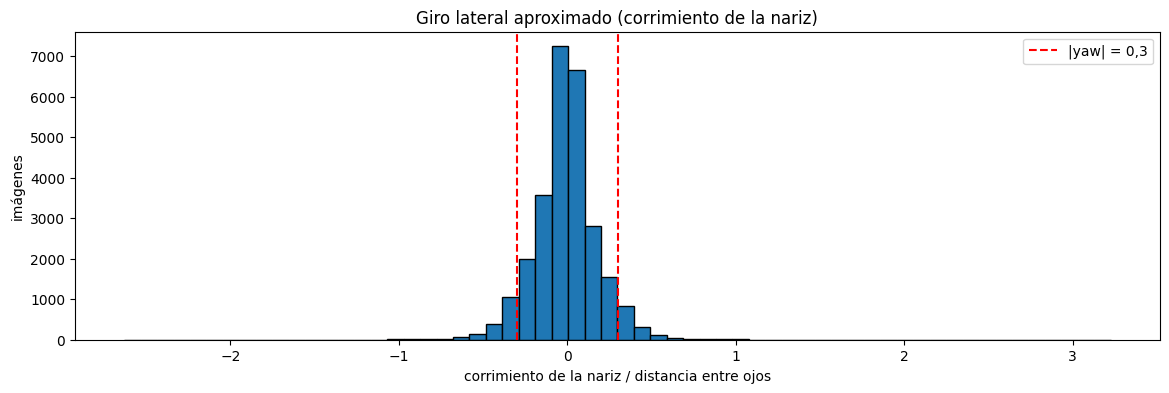

|yaw| > 0,3 (giro marcado): 2794 (10.38%)


In [58]:
interocular_distance = np.hypot(df["righteye_x"] - df["lefteye_x"], df["righteye_y"] - df["lefteye_y"])
df["yaw"] = (df["nose_x"] - (df["lefteye_x"] + df["righteye_x"]) / 2) / interocular_distance

plt.figure(figsize=(14, 4))
plt.hist(df["yaw"], bins=60, edgecolor="black")
plt.axvline(-0.3, color="red", ls="--")
plt.axvline(0.3, color="red", ls="--", label="|yaw| = 0,3")
plt.title("Giro lateral aproximado (corrimiento de la nariz)")
plt.xlabel("corrimiento de la nariz / distancia entre ojos")
plt.ylabel("imágenes")
plt.legend()
plt.show()

print(f"|yaw| > 0,3 (giro marcado): {(df['yaw'].abs() > 0.3).sum()} ({100 * (df['yaw'].abs() > 0.3).mean():.2f}%)")

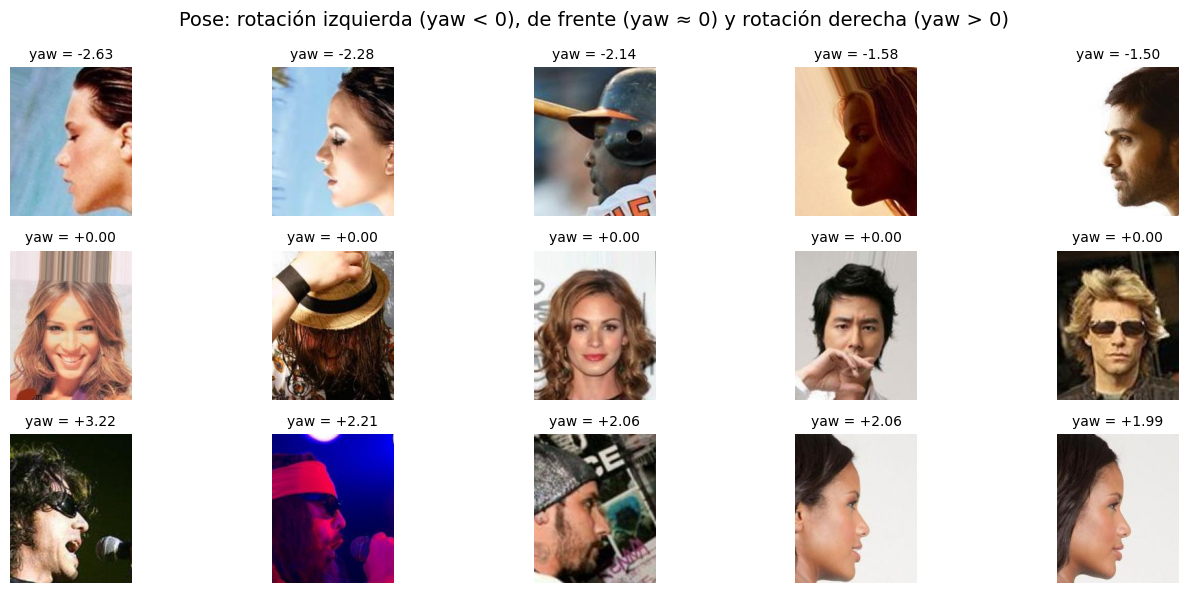

In [63]:
pose = {
    "Rotación izquierda (yaw negativo)": df.nsmallest(5, "yaw"),
    "De frente (yaw ≈ 0)": df.loc[df["yaw"].abs().nsmallest(5).index],
    "Rotación derecha (yaw positivo)": df.nlargest(5, "yaw"),
}

imgs, titles = [], []
for nombre, sub in pose.items():
    imgs += sub["src_path"].tolist()
    titles += [f"yaw = {v:+.2f}" for v in sub["yaw"]]

show_images(imgs, titles=titles, ncols=5, size=(14, 6), suptitle="Pose: rotación izquierda (yaw < 0), de frente (yaw ≈ 0) y rotación derecha (yaw > 0)")

#### Expresión y oclusiones

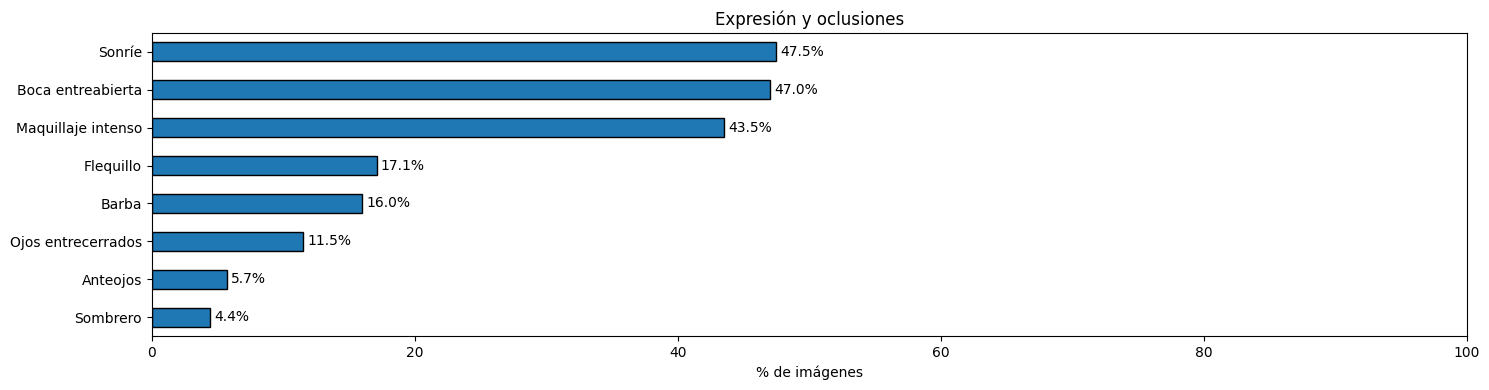

In [ ]:
atributos = pd.DataFrame({
    "Sonríe": df["Smiling"],
    "Boca entreabierta": df["Mouth_Slightly_Open"],
    "Ojos entrecerrados": df["Narrow_Eyes"],
    "Anteojos": df["Eyeglasses"],
    "Sombrero": df["Wearing_Hat"],
    "Flequillo": df["Bangs"],
    "Barba": 1 - df["No_Beard"],
    "Maquillaje intenso": df["Heavy_Makeup"]
})
prevalencia = (atributos.mean() * 100).round(1).sort_values()

ax = prevalencia.plot.barh(figsize=(15, 4), edgecolor="black")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_xlim(0, 100)
ax.set(title="Expresión y oclusiones", xlabel="% de imágenes")
plt.tight_layout()
plt.show()

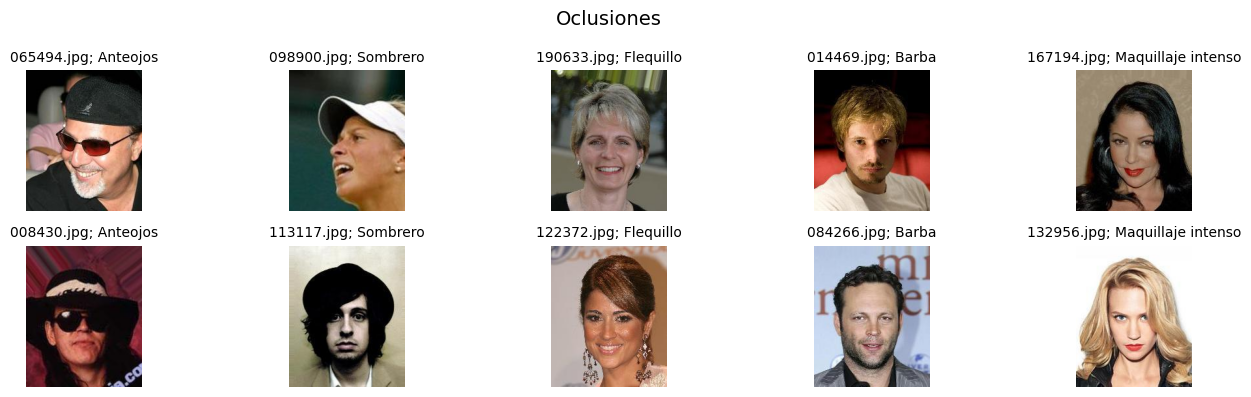

In [49]:
nombres = ["Anteojos", "Sombrero", "Flequillo", "Barba", "Maquillaje intenso"]
muestras = {nombre: df[atributos[nombre] == 1].sample(n=2, random_state=SEED) for nombre in nombres}

imgs, titles = [], []
for fila in range(2):
    for nombre in nombres:
        r = muestras[nombre].iloc[fila]
        imgs.append(r["src_path"])
        titles.append(f"{r['image_id']}; {nombre}")

show_images(imgs, titles=titles, ncols=len(nombres), size=(14, 4), suptitle="Oclusiones")

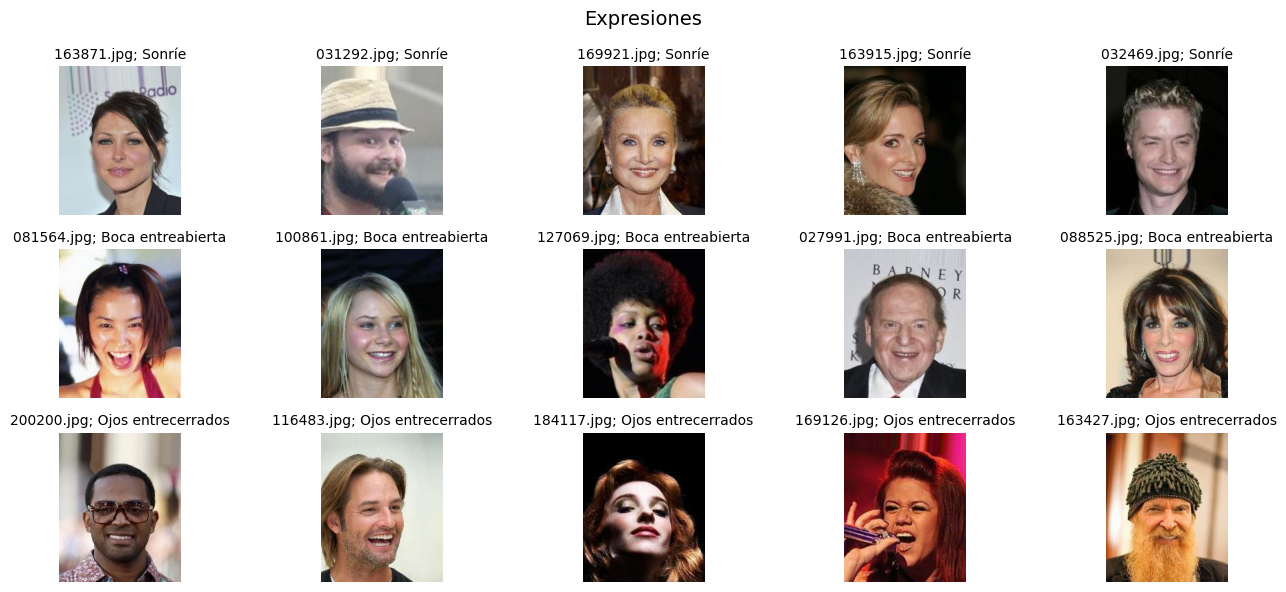

In [47]:
imgs, titles = [], []
for nombre in ["Sonríe", "Boca entreabierta", "Ojos entrecerrados"]:
    sub = df[atributos[nombre] == 1].sample(n=5, random_state=SEED)
    imgs += sub["src_path"].tolist()
    titles += [f"{i}; {nombre}" for i in sub["image_id"]]

show_images(imgs, titles=titles, ncols=5, size=(14, 6), suptitle="Expresiones")

## Detección y alineación (normalización)

## Control de calidad y limpieza

## Clustering exploratorio

## Data augmentation

## Partición de datos (splits)

## Licencias y términos de uso

El uso del dataset **CelebA** está sujeto a los términos establecidos por el [Multimedia Laboratory (MMLAB)](https://mmlab.ie.cuhk.edu.hk/) de [The Chinese University of Hong Kong](https://www.cuhk.edu.hk/english/index.html):
- El dataset debe ser utilizado únicamente con fines de investigación académica no comercial.
- Se acuerda no reproducir, duplicar, copiar, vender ni explotar con fines comerciales ninguna porción de las imágenes ni de los datos derivados.
- Se acuerda no copiar, publicar ni redistribuir ninguna porción del dataset de manera pública. Se exceptua el uso interno entre miembros del proyecto.
- Todas las imágenes son obtenidas de Internet y no son propiedad de MMLAB.

```bibtex
@inproceedings{liu2015faceattributes,
  title = {Deep Learning Face Attributes in the Wild},
  author = {Liu, Ziwei and Luo, Ping and Wang, Xiaogang and Tang, Xiaoou},
  booktitle = {Proceedings of International Conference on Computer Vision (ICCV)},
  month = {December},
  year = {2015} 
}
```

## Ética y privacidad

Las imágenes de rostros humanos constituyen **datos biométricos**, los cuales son considerados datos personales e **información sensible** según la [Ley 25.326 de Protección de Datos Personales](https://www.argentina.gob.ar/normativa/nacional/norma-64790) en **Argentina**.
Para garantizar que el desarrollo de este trabajo práctico no vulnere privacidades ni infrinja ninguna ley, utilizamos las imágenes únicamente de **forma local** y **temporal**, **sin exponer material** en el repositorio público y **sin vincularlas con datos de identidad reales**. A su vez, el procesamiento de estos datos **no persigue fines de lucro**.

Se reconoce explícitamente que CelebA presenta **sesgos demográficos** inherentes a su origen (fotografías de celebridades públicas de la industria del entretenimiento), lo que genera una representación dispar en términos de rangos etarios, condiciones de iluminación, origen étnico y géneros frente a una población general. Esto puede impactar en la **capacidad de generalización** del modelo ante escenarios de **aplicación real**.